# Fields

`px.PlotField` draws a simulation result on the planex2d geometry it was computed on, with colors over the faces,
contour lines, arrows and field lines. The call is the same for every solver: an NGSolve `GridFunction` or
`CoefficientFunction` and a FEniCSx `Function` are drawn alike, and `px.PlotMesh` draws the mesh of either. Every
pixel shows the field at its own point, evaluated by the solver, and only where both the face and the mesh are
present. The outlines are the exact edges of the geometry, not the edges of the mesh.

See [NGSolve](../../integrations/netgen/fields.md) for fields on curved meshes and cuts through 3D results, and
[gmsh and FEniCSx](../../integrations/fenicsx.md) for a dolfinx mesh made by gmsh, with the edge names as physical
groups. The [airplane windows example](../../examples/airplane-windows.md) draws the stress around windows of four
shapes.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import ngsolve as ngs
import gmsh
import ufl
import dolfinx
from dolfinx import fem
from dolfinx.fem.petsc import LinearProblem
from dolfinx.io import gmsh as gmshio
from mpi4py import MPI
import planex as px

In [2]:
import warnings

warnings.simplefilter("ignore", px.PlanexWarning)

## One plate, two solvers

The example is a plate of 3 × 2 with a hole of radius 0.5, held at 1 on its left edge `hot` and at 0 on its right
edge `cold`, while the other edges are insulated. The edges carry these names into both meshes, so both solvers set
their boundary values by name. Each solver solves Laplace's equation with second-order elements, and the two results
are compared by their conductance G, the integral of |∇u|².

In [3]:
s = px.QuickSketch().Line(3, name="wall").Line(0, 2, name="cold")
s.Line(-3, 0, name="wall").Close(name="hot").Circle(1.5, 1, 0.5, name="wall")
plate = s.Face()

netgen meshes the plate through `px.OCCGeometry`, and NGSolve solves on the curved mesh:

In [4]:
mesh = ngs.Mesh(px.OCCGeometry(plate).GenerateMesh(maxh=0.1))
mesh.Curve(2)
fes = ngs.H1(mesh, order=2, dirichlet="hot|cold")
u, v = fes.TnT()
a = ngs.BilinearForm(ngs.grad(u) * ngs.grad(v) * ngs.dx).Assemble()
gf = ngs.GridFunction(fes)
gf.Set(mesh.BoundaryCF({"hot": 1, "cold": 0}), ngs.BND)
gf.vec.data += a.mat.Inverse(fes.FreeDofs()) * (-a.mat * gf.vec)
G_ngsolve = ngs.Integrate(ngs.grad(gf) * ngs.grad(gf), mesh)

For FEniCSx, `WriteGeo` writes the plate as a gmsh `.geo` file, with the edge names as physical groups. gmsh meshes
it, and dolfinx solves on that mesh:

In [5]:
geo = os.path.join(tempfile.mkdtemp(), "plate.geo")
plate.WriteGeo(geo)
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.open(geo)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.1)
gmsh.model.mesh.generate(2)
gmsh.model.mesh.setOrder(2)
data = gmshio.model_to_mesh(gmsh.model, MPI.COMM_WORLD, 0, gdim=2)
gmsh.finalize()
V = fem.functionspace(data.mesh, ("Lagrange", 2))
bcs = []
for name, value in (("hot", 1.0), ("cold", 0.0)):
    dofs = fem.locate_dofs_topological(V, 1, data.facet_tags.find(data.physical_groups[name].tag))
    bcs.append(fem.dirichletbc(dolfinx.default_scalar_type(value), dofs, V))
p, q = ufl.TrialFunction(V), ufl.TestFunction(V)
zero = fem.Constant(data.mesh, dolfinx.default_scalar_type(0)) * q * ufl.dx
uh = LinearProblem(ufl.inner(ufl.grad(p), ufl.grad(q)) * ufl.dx, zero, bcs=bcs, petsc_options_prefix="plate_",
                   petsc_options={"ksp_type": "preonly", "pc_type": "lu"}).solve()
G_fenicsx = fem.assemble_scalar(fem.form(ufl.inner(ufl.grad(uh), ufl.grad(uh)) * ufl.dx))

print("G NGSolve", G_ngsolve, "FEniCSx", G_fenicsx)
print("relative difference", abs(G_ngsolve - G_fenicsx) / G_fenicsx)

G NGSolve 0.5014528302103062 FEniCSx 0.5014497411556131
relative difference 6.160247856386737e-06


The same call draws both results, each with ten contour lines:

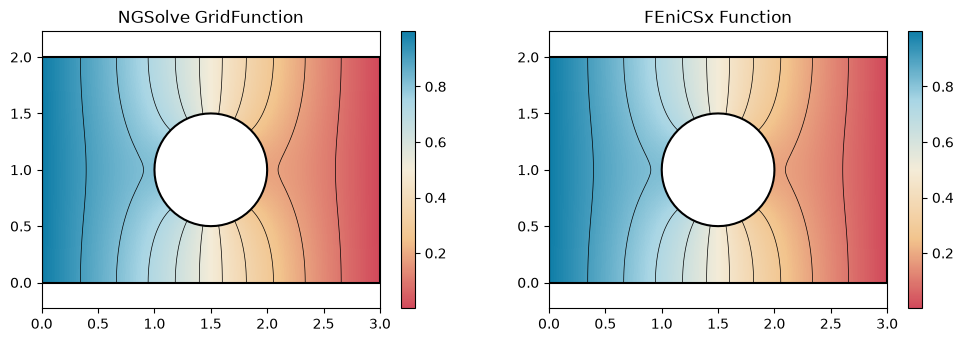

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
px.PlotField(gf, plate, ax=left, contours=10)
px.PlotField(uh, plate, ax=right, contours=10)
left.set_title("NGSolve GridFunction")
right.set_title("FEniCSx Function");

`px.PlotMesh` draws the two meshes over the plate, netgen's mesh curved along the hole and gmsh's mesh in dolfinx:

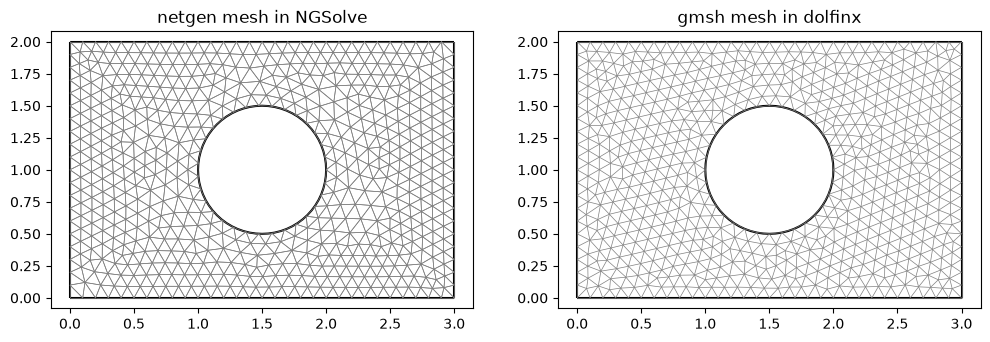

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
px.PlotMesh(mesh, plate, ax=left, legend=False)
px.PlotMesh(data.mesh, plate, ax=right, legend=False)
left.set_title("netgen mesh in NGSolve")
right.set_title("gmsh mesh in dolfinx");

## Vectors, field lines and colors

A vector field is drawn as its magnitude, and `vectors` and `field_lines` add its direction. The example is the heat
flux −∇u from NGSolve, a `CoefficientFunction`, so the mesh to evaluate it on is passed as well. It is drawn with
arrows (a), and with field lines and reversed colors (b). The flux crowds past the hole.

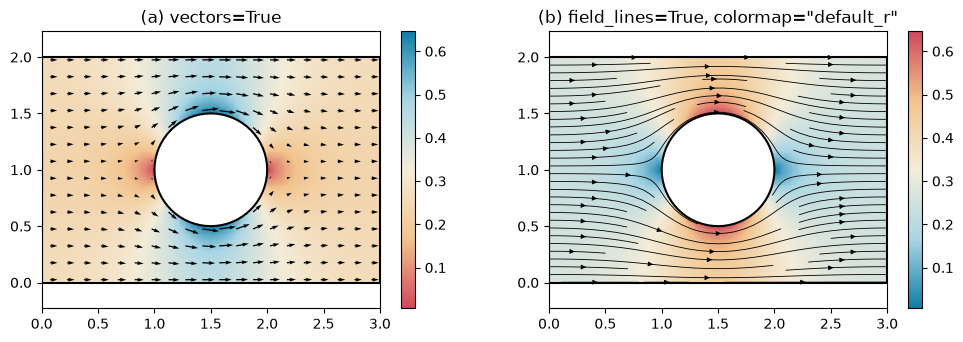

In [8]:
flux = -ngs.grad(gf)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
px.PlotField(flux, mesh, plate, ax=left, vectors=True)
px.PlotField(flux, mesh, plate, ax=right, field_lines=True, colormap="default_r")
left.set_title("(a) vectors=True")
right.set_title('(b) field_lines=True, colormap="default_r"');

`min` and `max` set the color range, as in NGSolve's `Draw`, and values outside it take the end colors. `contours`
also takes a list of levels, and `colormap` takes any matplotlib name. The example draws the FEniCSx result with a
narrower color range (a), and with three chosen levels in viridis (b).

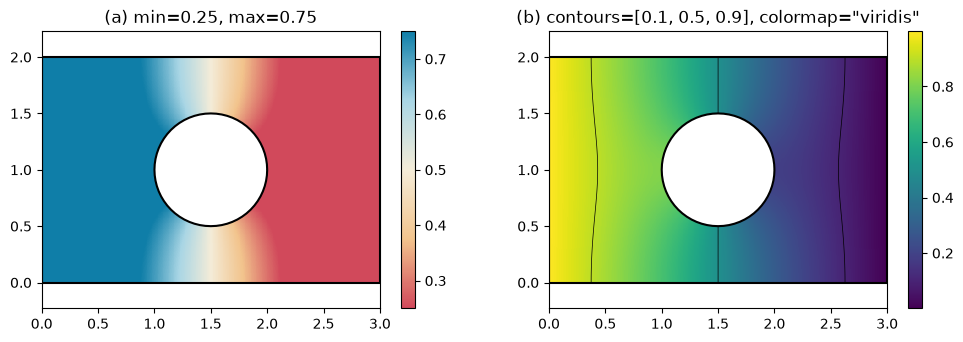

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
px.PlotField(uh, plate, ax=left, min=0.25, max=0.75)
px.PlotField(uh, plate, ax=right, contours=[0.1, 0.5, 0.9], colormap="viridis")
left.set_title("(a) min=0.25, max=0.75")
right.set_title('(b) contours=[0.1, 0.5, 0.9], colormap="viridis"');

## Options

| `px.PlotField(field, mesh, obj, ...)` | |
|---|---|
| `field` | An NGSolve `GridFunction` or `CoefficientFunction`, a dolfinx `Function`, or a measurement (see [Measurements](measurements.md)). |
| `mesh` | The mesh to evaluate a `CoefficientFunction` on; a `GridFunction` or `Function` brings its own. |
| `obj` | The planex2d object whose faces are colored, or a plane that cuts a 3D mesh. |
| `on` | `"faces"` (default) or `"edges"`: what a measurement colors. Solver fields always color the faces. |
| `contours` | n levels inside the color range, or a list of levels. |
| `vectors`, `field_lines` | Arrows, or field lines (`True` or a density), of a vector field. |
| `min`, `max`, `colormap` | The color range and the colors: `"default"`, `"default_r"`, a matplotlib name or a list. |
| `samples` | The number of pixels along the longer side (default 400). |
| `ax`, `backend`, `legend` | As for `px.Plot`. |